# Detección de grietas en hormigón con una CNN personalizada

Este notebook construye, entrena y evalúa **un único modelo: una red neuronal convolucional (Custom CNN) diseñada con capas de Keras**. No se utilizan modelos preentrenados ni se realizan comparaciones entre arquitecturas.

El flujo de trabajo es:

1. Importar librerías y localizar el conjunto de imágenes.
2. Explorar las imágenes y comprobar las clases.
3. Preparar etiquetas y dividir los datos en entrenamiento, validación y prueba.
4. Redimensionar y normalizar imágenes; crear lotes de datos.
5. Aplicar aumento de datos durante el entrenamiento.
6. Construir la CNN capa por capa.
7. Entrenar el modelo y guardar la mejor versión.
8. Evaluar el rendimiento con datos de prueba.
9. Analizar errores mediante matriz de confusión e informe de clasificación.
10. Interpretar algunas predicciones mediante Grad-CAM.

**Tarea:** clasificación binaria de superficies de hormigón: `Negative` (sin grieta visible) y `Positive` (con grieta visible). La predicción no sustituye la inspección ni el diagnóstico de un profesional estructural.

## 1. Importing Libraries and Basic Setup

In this section, the required Python libraries are imported. TensorFlow and Keras are used for CNN model development, scikit learn is used for evaluation metrics and dataset splitting, and Matplotlib is used for visualizing results.

In [1]:
import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

2026-06-04 18:19:20.269363: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780597160.435061      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780597160.481335      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780597160.866335      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780597160.866385      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780597160.866388      23 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Descargar el dataset desde Kaggle (Google Colab)

Estas celdas permiten descargar automáticamente el conjunto **Concrete Crack Images for Classification**. Antes de ejecutarlas, en Google Colab selecciona **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**, si está disponible.

Necesitas una credencial de Kaggle (`kaggle.json`). En Kaggle, abre tu perfil → Settings → API y genera/descarga el token API. No publiques ni compartas ese archivo: contiene credenciales privadas.

Dataset: [arnavr10880/concrete-crack-images-for-classification](https://www.kaggle.com/datasets/arnavr10880/concrete-crack-images-for-classification).

In [ ]:
!pip -q install kaggle

In [ ]:
from google.colab import files
from pathlib import Path
import os
import shutil

# Selecciona el archivo kaggle.json descargado desde Kaggle.
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise FileNotFoundError(
        "No se cargó kaggle.json. Vuelve a ejecutar esta celda y selecciona ese archivo."
    )

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
shutil.move("/content/kaggle.json", str(kaggle_dir / "kaggle.json"))
os.chmod(kaggle_dir / "kaggle.json", 0o600)
print("Credenciales de Kaggle configuradas.")

In [ ]:
from pathlib import Path
import subprocess

DATASET_DOWNLOAD_DIR = Path("/content/dataset")
DATASET_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Descarga y descomprime el dataset dentro de /content/dataset.
result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", "arnavr10880/concrete-crack-images-for-classification",
        "-p", str(DATASET_DOWNLOAD_DIR),
        "--unzip"
    ],
    text=True,
    capture_output=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        "Falló la descarga desde Kaggle. Verifica las credenciales y acepta las condiciones del dataset en Kaggle si se solicitan."
    )

print("Descarga y extracción completadas en:", DATASET_DOWNLOAD_DIR)

## 3. Localizar las carpetas de imágenes

El dataset puede incluir una carpeta raíz adicional al descomprimirse. Esta celda busca automáticamente las carpetas `Negative` y `Positive` y configura la ruta común que utilizarán las siguientes celdas.

In [ ]:
from pathlib import Path

DATASET_ROOT = Path("/content/dataset")
if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"No se encontró {DATASET_ROOT}. Ejecuta primero las celdas de descarga de Kaggle."
    )

negative_dirs = [p for p in DATASET_ROOT.rglob("Negative") if p.is_dir()]
positive_dirs = [p for p in DATASET_ROOT.rglob("Positive") if p.is_dir()]

# Busca una pareja Negative/Positive que comparta la misma carpeta padre.
class_pairs = [
    (neg.parent, neg, pos)
    for neg in negative_dirs
    for pos in positive_dirs
    if neg.parent == pos.parent
]

if not class_pairs:
    raise FileNotFoundError(
        "No se encontraron las carpetas Negative y Positive dentro de /content/dataset. "
        "Revisa la estructura del archivo descargado."
    )

input_root, negative_dir, positive_dir = class_pairs[0]
image_extensions = [".jpg", ".jpeg", ".png"]

print("Carpeta raíz detectada:", input_root)
for class_dir in (negative_dir, positive_dir):
    count = sum(
        1 for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )
    print(f"{class_dir.name}: {count} imágenes")

all_image_files = [
    p for p in input_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]
print("Total de imágenes encontradas:", len(all_image_files))
print("Primeras 5 rutas:")
for path in all_image_files[:5]:
    print(path)

In [3]:
class_folders = []

for folder in input_root.rglob("*"):
    if folder.is_dir():
        image_count = sum(
            1 for path in folder.iterdir()
            if path.is_file() and path.suffix.lower() in image_extensions
        )
        if image_count > 0:
            class_folders.append((folder, image_count))

print("Carpetas que contienen imágenes:")
for folder, count in class_folders:
    print(f"{folder} -> {count} imágenes")


Folders containing images:
/kaggle/input/datasets/arnavr10880/concrete-crack-images-for-classification/Negative -> 20000 images
/kaggle/input/datasets/arnavr10880/concrete-crack-images-for-classification/Positive -> 20000 images


## 3. Crear la tabla de imágenes y revisar las clases

Cada imagen se registra con su ruta y etiqueta, tomada del nombre de la carpeta que la contiene. Antes de entrenar, comprueba que las etiquetas encontradas sean exactamente `Negative` y `Positive` y revisa cuántas imágenes hay en cada clase.

In [4]:
data = []

for folder, count in class_folders:
    label = folder.name

    for image_path in folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            data.append({
                "image_path": str(image_path),
                "label": label
            })

df = pd.DataFrame(data)

print("Dimensiones del dataset:", df.shape)
print("\nDistribución de clases:")
print(df["label"].value_counts())

expected_classes = {"Negative", "Positive"}
found_classes = set(df["label"].unique())
if found_classes != expected_classes:
    raise ValueError(
        f"Se esperaban carpetas de clase {expected_classes}, pero se encontraron "
        f"{found_classes}. Revisa la estructura de carpetas del dataset."
    )

df.head()


Dataset shape: (40000, 2)

Class distribution:
label
Negative    20000
Positive    20000
Name: count, dtype: int64


,image_path,label
0,/kaggle/input/datasets/arnavr10880/concrete-cr...,Negative
1,/kaggle/input/datasets/arnavr10880/concrete-cr...,Negative
2,/kaggle/input/datasets/arnavr10880/concrete-cr...,Negative
3,/kaggle/input/datasets/arnavr10880/concrete-cr...,Negative
4,/kaggle/input/datasets/arnavr10880/concrete-cr...,Negative


## 4. Visualizar ejemplos

Se muestran algunas imágenes de cada clase para comprobar visualmente que las rutas y etiquetas sean coherentes antes de entrenar la red.

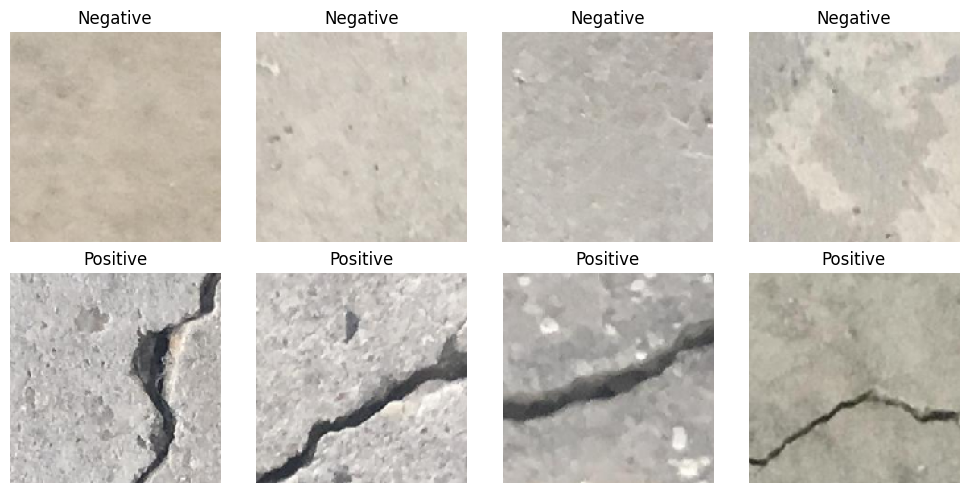

In [5]:
sample_df = df.groupby("label").sample(4, random_state=42)

plt.figure(figsize=(10, 5))

for i, row in enumerate(sample_df.itertuples(), 1):
    img = keras.utils.load_img(row.image_path, target_size=(160, 160))
    
    plt.subplot(2, 4, i)
    plt.imshow(img)
    plt.title(row.label)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Label Encoding

In this section, the text labels are converted into numerical labels for binary classification. Negative images are encoded as 0, and Positive images are encoded as 1.

In [6]:
label_map = {
    "Negative": 0,
    "Positive": 1
}

df["label_encoded"] = df["label"].map(label_map)

print(df.head())
print("\nEncoded class distribution:")
print(df["label_encoded"].value_counts())

                                          image_path     label  label_encoded
0  /kaggle/input/datasets/arnavr10880/concrete-cr...  Negative              0
1  /kaggle/input/datasets/arnavr10880/concrete-cr...  Negative              0
2  /kaggle/input/datasets/arnavr10880/concrete-cr...  Negative              0
3  /kaggle/input/datasets/arnavr10880/concrete-cr...  Negative              0
4  /kaggle/input/datasets/arnavr10880/concrete-cr...  Negative              0

Encoded class distribution:
label_encoded
0    20000
1    20000
Name: count, dtype: int64


## 6. Dividir los datos en entrenamiento, validación y prueba

Se reserva el 70 % de las imágenes para entrenamiento, el 15 % para validación y el 15 % para prueba. La división estratificada procura conservar la proporción de ambas clases en los tres subconjuntos.

La validación se usa durante el entrenamiento; el conjunto de prueba se reserva para la evaluación final.

In [7]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_encoded"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_encoded"],
    random_state=42
)

print("Train size:", train_df.shape)
print("Validation size:", val_df.shape)
print("Test size:", test_df.shape)

print("\nTrain class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

print("\nTest class distribution:")
print(test_df["label"].value_counts())

Train size: (28000, 3)
Validation size: (6000, 3)
Test size: (6000, 3)

Train class distribution:
label
Positive    14000
Negative    14000
Name: count, dtype: int64

Validation class distribution:
label
Negative    3000
Positive    3000
Name: count, dtype: int64

Test class distribution:
label
Positive    3000
Negative    3000
Name: count, dtype: int64


## 7. Preprocesar imágenes y crear los conjuntos de TensorFlow

Todas las imágenes se convierten a RGB, se redimensionan a `160 × 160` píxeles y se normalizan al rango `[0, 1]`. Luego se agrupan en lotes y se utiliza `prefetch` para preparar datos mientras TensorFlow procesa el lote actual.

In [8]:
IMG_SIZE = 160
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image, label

def create_tf_dataset(dataframe, shuffle=False):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label_encoded"].values
    
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    
    if shuffle:
        dataset = dataset.shuffle(buffer_size=2000, seed=42)
    
    dataset = dataset.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    
    return dataset

train_ds = create_tf_dataset(train_df, shuffle=True)
val_ds = create_tf_dataset(val_df, shuffle=False)
test_ds = create_tf_dataset(test_df, shuffle=False)

print("TensorFlow datasets created successfully.")

I0000 00:00:1780597238.468667      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1780597238.474691      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TensorFlow datasets created successfully.


## 8. Batch Verification

In this section, one batch from the training dataset is inspected. This confirms that images have the expected shape, labels have the correct format, and pixel values are properly normalized between 0 and 1.

In [9]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("First 10 labels:", labels.numpy()[:10])

Image batch shape: (32, 160, 160, 3)
Label batch shape: (32,)
Minimum pixel value: 0.003392201
Maximum pixel value: 1.0
First 10 labels: [0 0 1 0 1 0 1 1 0 1]


## 9. Output Folder Setup

In this section, output directories are created for saving figures, tables, and trained models. These saved outputs will be used later for the GitHub repository, proposal document, and final project report.

In [10]:
# Kaggle usa /kaggle/working; en Jupyter local se utiliza la carpeta actual.
kaggle_working = Path("/kaggle/working")
base_output = kaggle_working if kaggle_working.exists() else Path.cwd()

output_dir = base_output / "outputs"
figures_dir = output_dir / "figures"
tables_dir = output_dir / "tables"
models_dir = output_dir / "models"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

class_names = ["Negative", "Positive"]

print("Carpetas de salida:", output_dir.resolve())
print("Clases:", class_names)


Output folders created.
Class names: ['Negative', 'Positive']


## 10. Aumento de datos

Las transformaciones aleatorias —volteo horizontal, rotación, zoom y contraste— se aplican durante el entrenamiento. No crean nuevas etiquetas: generan variaciones de las imágenes de entrenamiento para ayudar al modelo a generalizar.

In [11]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.10),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ],
    name="data_augmentation"
)

print("Data augmentation layer created.")

Data augmentation layer created.


## 11. Construir la Custom CNN capa por capa

La red se define desde cero usando capas de Keras. La arquitectura contiene cuatro bloques convolucionales; cada bloque extrae características visuales y reduce la resolución mediante *MaxPooling*.

- **Conv2D (32, 64, 128 y 256 filtros):** aprende patrones visuales cada vez más complejos.
- **MaxPooling2D:** reduce las dimensiones espaciales de los mapas de características.
- **GlobalAveragePooling2D:** resume cada mapa de características en un valor.
- **Dense (128 neuronas, ReLU):** combina las características extraídas.
- **Dropout (0.40):** desactiva aleatoriamente parte de las activaciones durante el entrenamiento para ayudar a reducir el sobreajuste.
- **Dense (1 neurona, sigmoide):** produce una probabilidad entre 0 y 1 para la clase `Positive`.

El aumento de datos se integra al principio de la red y solo se aplica en modo entrenamiento.

In [ ]:
def build_custom_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    model = keras.Sequential(
        [
            layers.Input(shape=input_shape),
            
            data_augmentation,
            
            layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            
            layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            
            layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            
            layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            
            layers.GlobalAveragePooling2D(),
            
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.40),
            
            layers.Dense(1, activation="sigmoid")
        ],
        name="custom_cnn_concrete_crack_detection"
    )
    
    return model

custom_cnn = build_custom_cnn()

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()

Model: "custom_cnn_concrete_crack_detection"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## 12. Entrenar la Custom CNN

El modelo aprende usando `train_ds` y se monitoriza con `val_ds`. `EarlyStopping` detiene el entrenamiento si la pérdida de validación deja de mejorar; `ModelCheckpoint` guarda la mejor versión según esa misma métrica.

El número máximo de épocas está fijado en 10 y puede ajustarse según los resultados y los recursos disponibles.

In [13]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(models_dir / "best_custom_cnn.keras"),
    monitor="val_loss",
    save_best_only=True
)

history_custom_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, model_checkpoint]
)

Epoch 1/10


I0000 00:00:1780597246.356776      73 cuda_dnn.cc:529] Loaded cuDNN version 91002


875/875 ━━━━━━━━━━━━━━━━━━━━ 44s 43ms/step - accuracy: 0.9549 - loss: 0.1093 - val_accuracy: 0.9420 - val_loss: 0.2055
Epoch 2/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step - accuracy: 0.9841 - loss: 0.0518 - val_accuracy: 0.9875 - val_loss: 0.0469
Epoch 3/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step - accuracy: 0.9889 - loss: 0.0373 - val_accuracy: 0.9877 - val_loss: 0.0376
Epoch 4/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 30s 35ms/step - accuracy: 0.9901 - loss: 0.0310 - val_accuracy: 0.9922 - val_loss: 0.0316
Epoch 5/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.9939 - loss: 0.0207 - val_accuracy: 0.9878 - val_loss: 0.0398
Epoch 6/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.9958 - loss: 0.0165 - val_accuracy: 0.9947 - val_loss: 0.0190
Epoch 7/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.9962 - loss: 0.0136 - val_accuracy: 0.9973 - val_loss: 0.0089
Epoch 8/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.9959 - loss: 0.0133 - val_accurac

## 13. Evaluación final con el conjunto de prueba

Se carga la mejor versión guardada de la Custom CNN y se evalúa una sola vez sobre el conjunto de prueba reservado. La pérdida y la exactitud resultantes estiman el rendimiento sobre imágenes no utilizadas para actualizar los pesos.

In [14]:
best_custom_cnn = keras.models.load_model(models_dir / "best_custom_cnn.keras")

custom_test_loss, custom_test_accuracy = best_custom_cnn.evaluate(test_ds)

print("Custom CNN Test Loss:", custom_test_loss)
print("Custom CNN Test Accuracy:", custom_test_accuracy)

188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.9977 - loss: 0.0068
Custom CNN Test Loss: 0.0068212030455470085
Custom CNN Test Accuracy: 0.9976666569709778


## 14. Visualizar las curvas de entrenamiento

Se grafican la exactitud y la pérdida de entrenamiento y validación por época. Si la exactitud de entrenamiento sigue aumentando mientras la de validación se estanca o empeora, puede haber sobreajuste.

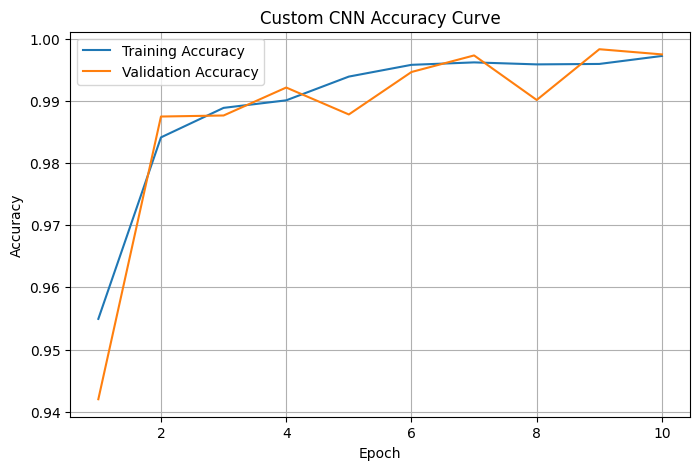

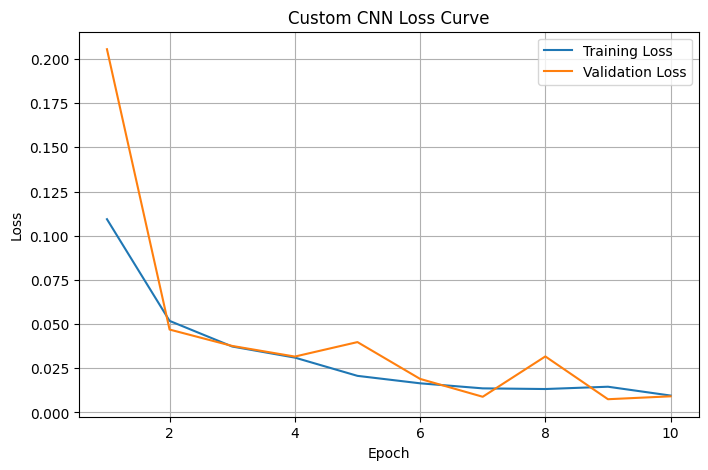

In [15]:
def plot_training_curves(history, model_name, save_path):
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    
    epochs_range = range(1, len(acc) + 1)
    
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_range, acc, label="Training Accuracy")
    plt.plot(epochs_range, val_acc, label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{model_name} Accuracy Curve")
    plt.legend()
    plt.grid(True)
    plt.savefig(save_path / f"{model_name.lower().replace(' ', '_')}_accuracy_curve.png", dpi=300, bbox_inches="tight")
    plt.show()
    
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_range, loss, label="Training Loss")
    plt.plot(epochs_range, val_loss, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{model_name} Loss Curve")
    plt.legend()
    plt.grid(True)
    plt.savefig(save_path / f"{model_name.lower().replace(' ', '_')}_loss_curve.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_training_curves(history_custom_cnn, "Custom CNN", figures_dir)

## 15. Generar predicciones y calcular la matriz de confusión

La CNN predice la probabilidad de que cada imagen de prueba pertenezca a `Positive`. Se aplica un umbral de 0.5 para convertir esas probabilidades en etiquetas binarias y comparar las predicciones con las etiquetas reales.

In [16]:
y_true = np.concatenate([labels.numpy() for images, labels in test_ds], axis=0)

y_prob_custom = best_custom_cnn.predict(test_ds)
y_pred_custom = (y_prob_custom.ravel() >= 0.5).astype(int)

cm_custom = confusion_matrix(y_true, y_pred_custom)

print("Confusion Matrix:")
print(cm_custom)

188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step
Confusion Matrix:
[[2992    8]
 [   6 2994]]


## 16. Custom CNN Confusion Matrix Visualization

In this section, the confusion matrix of the custom CNN model is visualized and saved as a figure. This visualization helps clearly show the number of correct and incorrect predictions for each class.

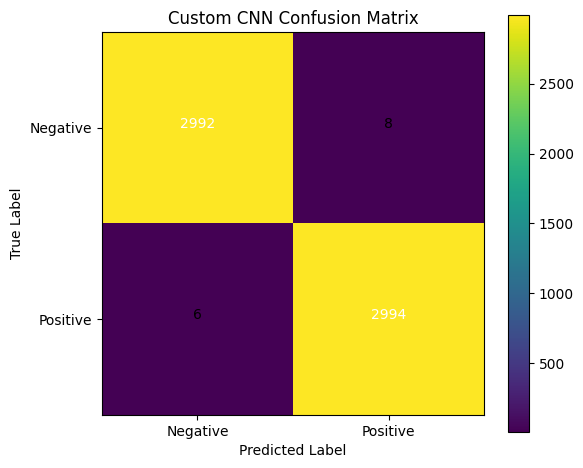

In [17]:
plt.figure(figsize=(6, 5))
plt.imshow(cm_custom, interpolation="nearest")
plt.title("Custom CNN Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

threshold = cm_custom.max() / 2

for i in range(cm_custom.shape[0]):
    for j in range(cm_custom.shape[1]):
        plt.text(
            j,
            i,
            cm_custom[i, j],
            horizontalalignment="center",
            color="white" if cm_custom[i, j] > threshold else "black"
        )

plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig(figures_dir / "custom_cnn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 17. Custom CNN Classification Report

In this section, a classification report is generated for the custom CNN model. Precision, recall, F1 score, and support values are calculated for both Negative and Positive classes, and the report is saved as a CSV table.

In [18]:
custom_report = classification_report(
    y_true,
    y_pred_custom,
    target_names=class_names,
    output_dict=True
)

custom_report_df = pd.DataFrame(custom_report).transpose()
custom_report_df.to_csv(tables_dir / "custom_cnn_classification_report.csv")

custom_report_df

,precision,recall,f1-score,support
Negative,0.997999,0.997333,0.997666,3000.000000
Positive,0.997335,0.998000,0.997667,3000.000000
accuracy,0.997667,0.997667,0.997667,0.997667
macro avg,0.997667,0.997667,0.997667,6000.000000
weighted avg,0.997667,0.997667,0.997667,6000.000000


## 18. Interpretabilidad con Grad-CAM

Grad-CAM genera un mapa aproximado de las regiones de la imagen que más contribuyeron a la predicción de la CNN. Es una herramienta de interpretación visual, no una segmentación exacta de la grieta ni una prueba de causalidad.

In [28]:
last_conv_layer_name = None

for layer in reversed(best_custom_cnn.layers):
    if isinstance(layer, layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print("Last convolution layer for Custom CNN Grad CAM:", last_conv_layer_name)

Last convolution layer for Custom CNN Grad CAM: conv2d_3


## 19. Custom CNN Grad CAM Forward Function

In this section, a custom Grad CAM forward function is created for the saved Custom CNN model. This function extracts the feature maps from the last convolutional layer and connects them to the final prediction output for Grad CAM heatmap generation.

In [29]:

dummy_input = tf.zeros((1, IMG_SIZE, IMG_SIZE, 3))
_ = best_custom_cnn(dummy_input, training=False)

# Find index of the last convolution layer
last_conv_index = None

for i, layer in enumerate(best_custom_cnn.layers):
    if layer.name == last_conv_layer_name:
        last_conv_index = i
        break

print("Last convolution layer name:", last_conv_layer_name)
print("Last convolution layer index:", last_conv_index)

# Layers before and including the last convolution layer
feature_layers = best_custom_cnn.layers[:last_conv_index + 1]

# Layers after the last convolution layer
classifier_layers = best_custom_cnn.layers[last_conv_index + 1:]

def custom_gradcam_forward(image_tensor):
    x = image_tensor
    
    for layer in feature_layers:
        if isinstance(layer, keras.Sequential):
            x = layer(x, training=False)
        else:
            x = layer(x, training=False)
    
    conv_outputs = x
    
    for layer in classifier_layers:
        if isinstance(layer, layers.Dropout):
            x = layer(x, training=False)
        else:
            x = layer(x, training=False)
    
    predictions = x
    
    return conv_outputs, predictions

print("Custom CNN Grad CAM forward function created successfully.")

Last convolution layer name: conv2d_3
Last convolution layer index: 7
Custom CNN Grad CAM forward function created successfully.


## 20. Grad CAM Sample Selection

In this section, representative test images are selected for Grad CAM visualization. The selected examples include one correct Positive prediction, one correct Negative prediction, one false Positive prediction, and one false Negative prediction to support both explainability and error analysis.

In [30]:
test_results_custom_df = test_df.copy().reset_index(drop=True)

test_results_custom_df["true_label_encoded"] = y_true
test_results_custom_df["predicted_label_encoded"] = y_pred_custom
test_results_custom_df["predicted_probability_positive"] = y_prob_custom.ravel()

test_results_custom_df["true_label"] = test_results_custom_df["true_label_encoded"].map({0: "Negative", 1: "Positive"})
test_results_custom_df["predicted_label"] = test_results_custom_df["predicted_label_encoded"].map({0: "Negative", 1: "Positive"})

true_positive_custom = test_results_custom_df[
    (test_results_custom_df["true_label_encoded"] == 1) &
    (test_results_custom_df["predicted_label_encoded"] == 1)
].head(1)

true_negative_custom = test_results_custom_df[
    (test_results_custom_df["true_label_encoded"] == 0) &
    (test_results_custom_df["predicted_label_encoded"] == 0)
].head(1)

false_positive_custom = test_results_custom_df[
    (test_results_custom_df["true_label_encoded"] == 0) &
    (test_results_custom_df["predicted_label_encoded"] == 1)
].head(1)

false_negative_custom = test_results_custom_df[
    (test_results_custom_df["true_label_encoded"] == 1) &
    (test_results_custom_df["predicted_label_encoded"] == 0)
].head(1)

gradcam_custom_samples = pd.concat(
    [
        true_positive_custom,
        true_negative_custom,
        false_positive_custom,
        false_negative_custom
    ],
    axis=0
).reset_index(drop=True)

gradcam_custom_samples[
    [
        "image_path",
        "true_label",
        "predicted_label",
        "predicted_probability_positive"
    ]
]

,image_path,true_label,predicted_label,predicted_probability_positive
0,/kaggle/input/datasets/arnavr10880/concrete-cr...,Positive,Positive,0.999990
1,/kaggle/input/datasets/arnavr10880/concrete-cr...,Negative,Negative,0.000217
2,/kaggle/input/datasets/arnavr10880/concrete-cr...,Negative,Positive,0.925413
3,/kaggle/input/datasets/arnavr10880/concrete-cr...,Positive,Negative,0.306108


## 21. Grad CAM Heatmap Generation and Visualization

In this section, Grad CAM heatmaps are generated for the selected test images. The original image, Grad CAM heatmap, and overlay visualization are shown side by side. These visualizations help interpret the Custom CNN model by showing which regions contributed most to its predictions.

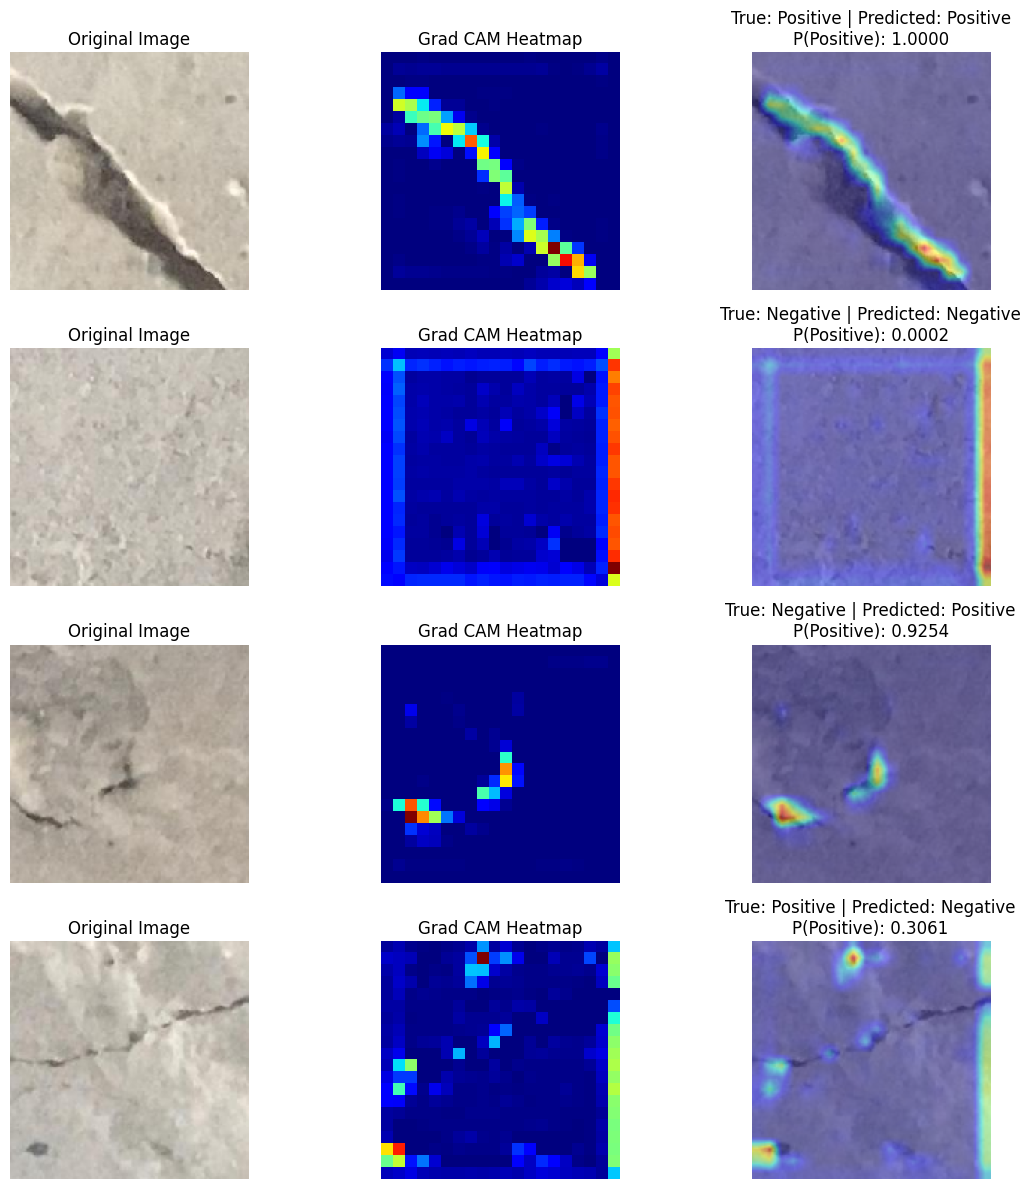

In [31]:
def load_image_for_gradcam(image_path):
    image = keras.utils.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    image_array = keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    return image_array

def make_custom_gradcam_heatmap(image_array, predicted_class):
    image_tensor = np.expand_dims(image_array, axis=0)
    image_tensor = tf.convert_to_tensor(image_tensor, dtype=tf.float32)
    
    with tf.GradientTape() as tape:
        conv_outputs, predictions = custom_gradcam_forward(image_tensor)
        
        if predicted_class == 1:
            class_score = predictions[:, 0]
        else:
            class_score = 1.0 - predictions[:, 0]
    
    gradients = tape.gradient(class_score, conv_outputs)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))
    
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_gradients, axis=-1)
    
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    
    return heatmap.numpy()

def overlay_heatmap_on_image(image_array, heatmap, alpha=0.45):
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (IMG_SIZE, IMG_SIZE)
    ).numpy().squeeze()
    
    colored_heatmap = plt.cm.jet(heatmap_resized)[..., :3]
    overlay = (1 - alpha) * image_array + alpha * colored_heatmap
    overlay = np.clip(overlay, 0, 1)
    
    return overlay

plt.figure(figsize=(12, 12))

for idx, row in gradcam_custom_samples.iterrows():
    image_array = load_image_for_gradcam(row["image_path"])
    predicted_class = int(row["predicted_label_encoded"])
    
    heatmap = make_custom_gradcam_heatmap(image_array, predicted_class)
    overlay = overlay_heatmap_on_image(image_array, heatmap)
    
    title_text = (
        f"True: {row['true_label']} | Predicted: {row['predicted_label']}\n"
        f"P(Positive): {row['predicted_probability_positive']:.4f}"
    )
    
    plt.subplot(len(gradcam_custom_samples), 3, idx * 3 + 1)
    plt.imshow(image_array)
    plt.title("Original Image")
    plt.axis("off")
    
    plt.subplot(len(gradcam_custom_samples), 3, idx * 3 + 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title("Grad CAM Heatmap")
    plt.axis("off")
    
    plt.subplot(len(gradcam_custom_samples), 3, idx * 3 + 3)
    plt.imshow(overlay)
    plt.title(title_text)
    plt.axis("off")

plt.tight_layout()
plt.savefig(figures_dir / "custom_cnn_gradcam_examples.png", dpi=300, bbox_inches="tight")
plt.show()

## 22. Archivos generados

Esta sección enumera las figuras generadas por el flujo de trabajo de la Custom CNN. Los resultados se guardan en las carpetas `figures`, `tables` y `models` dentro de `outputs`.

In [ ]:
print("Saved Custom CNN figures:")
for file in sorted(figures_dir.glob("custom_cnn_*")):
    print(file.name)

## 23. Explorador interactivo de imágenes: predicción + Grad-CAM

Al terminar el entrenamiento, selecciona un número entre **1 y el total de imágenes del dataset**. La celda mostrará la imagen original, el mapa de calor Grad-CAM, la superposición del mapa sobre la imagen y la predicción de la Custom CNN.

- **Etiqueta real:** clase indicada por la carpeta (`Positive` o `Negative`).
- **Predicción:** clase que estima la red con umbral de probabilidad 0,5.
- **P(Positive):** probabilidad estimada de que la imagen contenga una grieta.
- **Grad-CAM:** visualización aproximada de las regiones que contribuyen a la predicción; no es una medición física de la grieta.

El selector recorre todas las imágenes disponibles en `df`, no solamente las imágenes de prueba. Para una evaluación imparcial, recuerda que las métricas del modelo se calculan por separado sobre `test_df`.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Comprueba que el modelo y las funciones de Grad-CAM ya estén definidos.
required_objects = [
    "df", "best_custom_cnn", "load_image_for_gradcam",
    "make_custom_gradcam_heatmap", "overlay_heatmap_on_image"
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan objetos necesarios: " + ", ".join(missing_objects) +
        ". Ejecuta las celdas anteriores en orden."
    )

# Orden estable para que cada número corresponda siempre a la misma imagen.
interactive_images = (
    df[["image_path", "label"]]
    .drop_duplicates(subset=["image_path"])
    .sort_values("image_path")
    .reset_index(drop=True)
)

def show_selected_image(image_number):
    # El usuario selecciona del 1 al total; Python indexa desde 0.
    row = interactive_images.iloc[int(image_number) - 1]
    image_path = row["image_path"]
    true_label = str(row["label"])

    image_array = load_image_for_gradcam(image_path)
    prediction_probability = float(
        best_custom_cnn.predict(
            np.expand_dims(image_array, axis=0), verbose=0
        )[0][0]
    )
    predicted_class = int(prediction_probability >= 0.5)
    predicted_label = "Positive" if predicted_class == 1 else "Negative"

    heatmap = make_custom_gradcam_heatmap(image_array, predicted_class)
    overlay = overlay_heatmap_on_image(image_array, heatmap)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image_array)
    axes[0].set_title(f"Imagen original\nEtiqueta real: {true_label}")

    axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Mapa de calor Grad-CAM")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Predicción: {predicted_label}\n"
        f"P(Positive) = {prediction_probability:.2%}"
    )

    for ax in axes:
        ax.axis("off")

    result_text = (
        f"Imagen {int(image_number)} de {len(interactive_images)}\n"
        f"Etiqueta real: {true_label} | Predicción: {predicted_label} | "
        f"P(Positive): {prediction_probability:.2%}\n"
        f"Resultado: {'Grieta detectada' if predicted_class == 1 else 'No se detectó grieta'}"
    )
    fig.suptitle(result_text, fontsize=12)
    plt.tight_layout()
    plt.show()

    if predicted_label == true_label:
        print("Predicción correcta respecto a la etiqueta del dataset.")
    else:
        print("Predicción incorrecta respecto a la etiqueta del dataset.")

image_selector = widgets.IntSlider(
    value=1,
    min=1,
    max=len(interactive_images),
    step=1,
    description="Imagen #",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="80%")
)

display(widgets.interactive(
    show_selected_image,
    image_number=image_selector
))


## 24. Probar una imagen externa (no incluida en el dataset)

Esta celda permite subir una fotografía propia desde el ordenador y evaluarla con la **Custom CNN ya entrenada**, sin volver a entrenar el modelo. Muestra la imagen, el mapa Grad-CAM y la predicción (`Positive`: grieta; `Negative`: no se detectó grieta).

> La imagen debe mostrar una superficie de hormigón similar a las del dataset. La predicción es experimental y no sustituye una inspección estructural profesional. Grad-CAM es una visualización orientativa de las regiones que influyen en la predicción, no una segmentación exacta de la grieta.


In [ ]:
from google.colab import files
from PIL import Image
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Verificar que el modelo entrenado y las funciones Grad-CAM estén disponibles.
required_objects = [
    "best_custom_cnn",
    "make_custom_gradcam_heatmap",
    "overlay_heatmap_on_image",
    "IMG_SIZE"
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan objetos necesarios: " + ", ".join(missing_objects) +
        ". Ejecuta las celdas anteriores en orden hasta cargar el modelo."
    )

print("Selecciona una imagen de hormigón desde tu ordenador.")
uploaded_external = files.upload()

if not uploaded_external:
    print("No se ha seleccionado ningún archivo.")
else:
    # Procesar la primera imagen subida.
    valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    image_name = next(
        (name for name in uploaded_external
         if name.lower().endswith(valid_extensions)),
        None
    )

    if image_name is None:
        raise ValueError(
            "Formato no compatible. Sube una imagen JPG, JPEG, PNG, BMP o WEBP."
        )

    # Conservar la imagen original para mostrarla y preparar una copia para la CNN.
    original_image = Image.open(BytesIO(uploaded_external[image_name])).convert("RGB")
    model_image = original_image.resize((IMG_SIZE, IMG_SIZE))
    image_array = np.asarray(model_image, dtype=np.float32) / 255.0

    # Inferencia con el modelo ya entrenado.
    probability_positive = float(
        best_custom_cnn.predict(
            np.expand_dims(image_array, axis=0),
            verbose=0
        ).ravel()[0]
    )
    predicted_class = int(probability_positive >= 0.5)
    predicted_label = "Positive (grieta)" if predicted_class == 1 else "Negative (sin grieta)"

    # Grad-CAM para la clase predicha.
    heatmap = make_custom_gradcam_heatmap(image_array, predicted_class)
    overlay = overlay_heatmap_on_image(image_array, heatmap)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].imshow(original_image)
    axes[0].set_title("Imagen subida")
    axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Mapa de calor Grad-CAM")
    axes[2].imshow(overlay)
    axes[2].set_title("Superposición + predicción")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{image_name}\nPredicción: {predicted_label} | "
        f"Probabilidad Positive: {probability_positive:.2%}",
        fontsize=12
    )
    plt.tight_layout()
    plt.show()

    print(f"Archivo: {image_name}")
    print(f"Predicción de la Custom CNN: {predicted_label}")
    print(f"Probabilidad estimada de Positive (grieta): {probability_positive:.2%}")
    print(
        "Resultado del modelo: "
        + ("Grieta detectada." if predicted_class == 1
           else "No se detectó grieta.")
    )
    print(
        "Nota: esta es una clasificación experimental; "
        "no garantiza la detección correcta en fotografías reales."
    )
